In [ ]:
import pandas as pd

df = pd.read_csv('accepted_2007_to_2018Q4.csv', low_memory=False)
print("Shape:", df.shape)
print(df.head(3))

Shape: (635342, 151)
         id  member_id  loan_amnt  funded_amnt  funded_amnt_inv        term  \
0  68407277        NaN     3600.0       3600.0           3600.0   36 months   
1  68355089        NaN    24700.0      24700.0          24700.0   36 months   
2  68341763        NaN    20000.0      20000.0          20000.0   60 months   

   int_rate  installment grade sub_grade  ... hardship_payoff_balance_amount  \
0     13.99       123.03     C        C4  ...                            NaN   
1     11.99       820.28     C        C1  ...                            NaN   
2     10.78       432.66     B        B4  ...                            NaN   

  hardship_last_payment_amount disbursement_method  debt_settlement_flag  \
0                          NaN                Cash                     N   
1                          NaN                Cash                     N   
2                          NaN                Cash                     N   

  debt_settlement_flag_date settleme

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported")

All libraries imported


In [ ]:
# Keep only needed columns
cols = [
    'loan_amnt', 'int_rate', 'installment', 'annual_inc',
    'dti', 'fico_range_low', 'term', 'emp_length',
    'home_ownership', 'purpose', 'open_acc',
    'revol_util', 'total_acc', 'loan_status'
]

df = df[cols].copy()

# Drop rows with missing values
df.dropna(inplace=True)

# Keep only fully paid or charged off loans
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])]

print("Shape after cleaning:", df.shape)
print(df['loan_status'].value_counts())

Shape after cleaning: (408504, 14)
loan_status
Fully Paid     326542
Charged Off     81962
Name: count, dtype: int64


In [ ]:
df['prepaid'] = (df['loan_status'] == 'Fully Paid').astype(int)

# Clean term — extract number
df['term'] = df['term'].str.strip().str.replace(' months', '').astype(int)

# Clean emp_length
df['emp_length'] = df['emp_length'].str.extract('(\d+)').astype(float)
df['emp_length'].fillna(0, inplace=True)

# Rename fico column
df.rename(columns={'fico_range_low': 'fico_score'}, inplace=True)

print("Target distribution:")
print(df['prepaid'].value_counts())
print(f"\nPrepayment rate: {df['prepaid'].mean():.2%}")

Target distribution:
prepaid
1    326542
0     81962
Name: count, dtype: int64

Prepayment rate: 79.94%


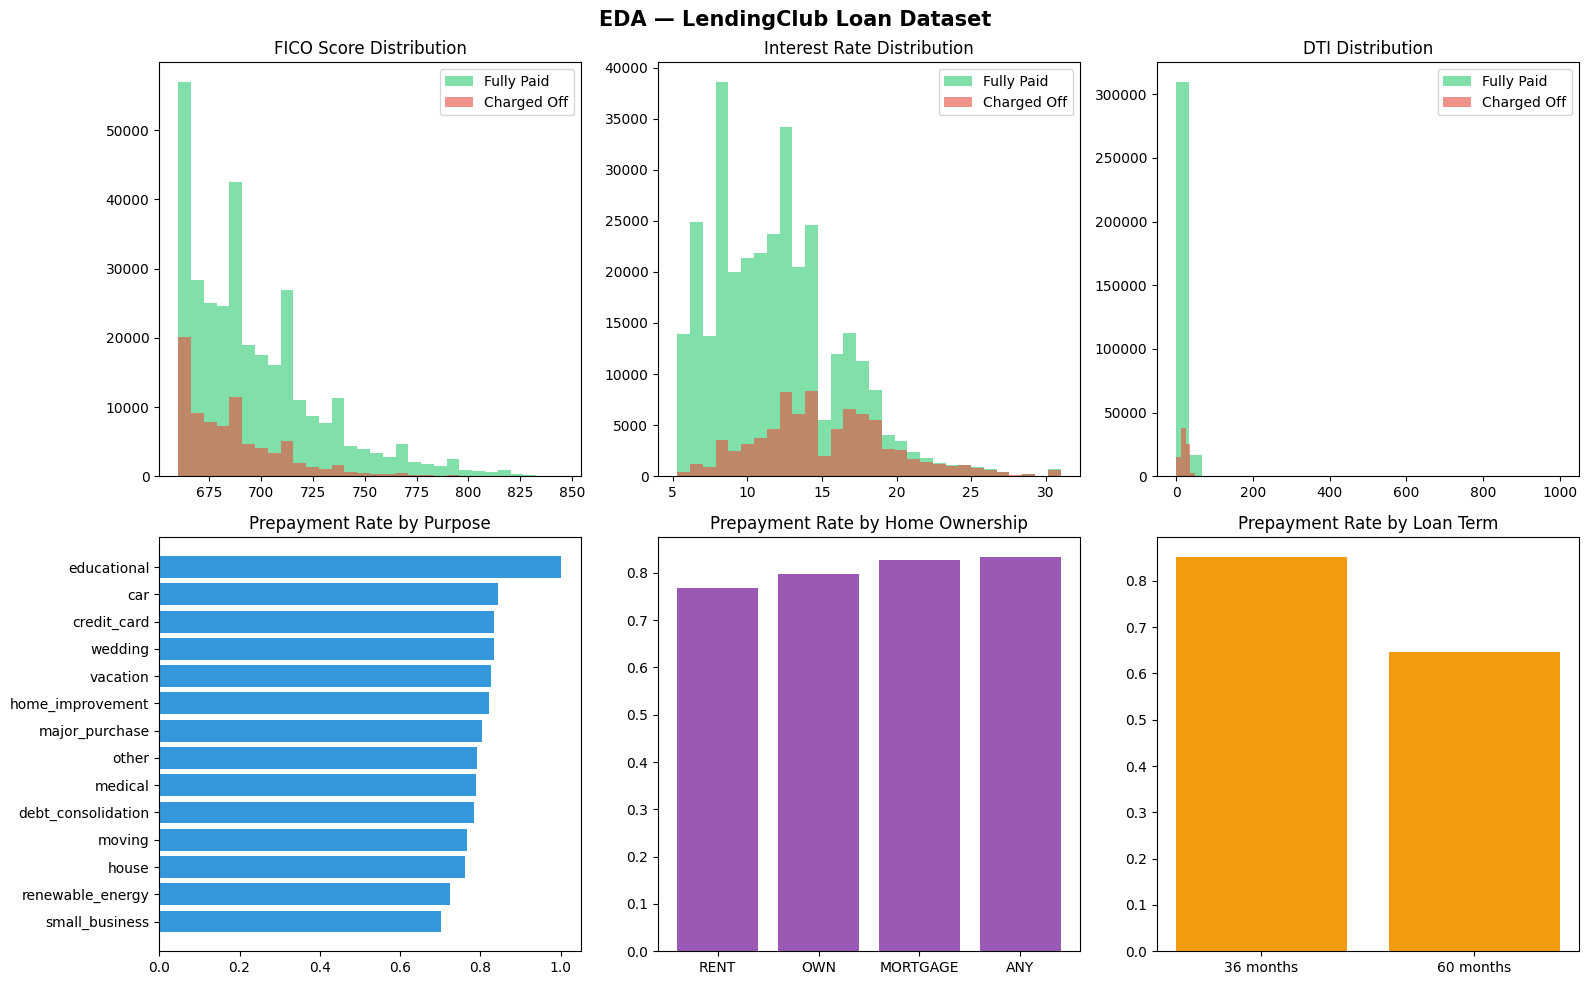

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('EDA — LendingClub Loan Dataset', fontsize=15, fontweight='bold')

# FICO Score
axes[0,0].hist(df[df['prepaid']==1]['fico_score'], bins=30, alpha=0.6, label='Fully Paid', color='#2ecc71')
axes[0,0].hist(df[df['prepaid']==0]['fico_score'], bins=30, alpha=0.6, label='Charged Off', color='#e74c3c')
axes[0,0].set_title('FICO Score Distribution')
axes[0,0].legend()

# Interest Rate
axes[0,1].hist(df[df['prepaid']==1]['int_rate'], bins=30, alpha=0.6, label='Fully Paid', color='#2ecc71')
axes[0,1].hist(df[df['prepaid']==0]['int_rate'], bins=30, alpha=0.6, label='Charged Off', color='#e74c3c')
axes[0,1].set_title('Interest Rate Distribution')
axes[0,1].legend()

# DTI
axes[0,2].hist(df[df['prepaid']==1]['dti'], bins=30, alpha=0.6, label='Fully Paid', color='#2ecc71')
axes[0,2].hist(df[df['prepaid']==0]['dti'], bins=30, alpha=0.6, label='Charged Off', color='#e74c3c')
axes[0,2].set_title('DTI Distribution')
axes[0,2].legend()

# Purpose
purpose_prepay = df.groupby('purpose')['prepaid'].mean().sort_values()
axes[1,0].barh(purpose_prepay.index, purpose_prepay.values, color='#3498db')
axes[1,0].set_title('Prepayment Rate by Purpose')

# Home Ownership
home_prepay = df.groupby('home_ownership')['prepaid'].mean().sort_values()
axes[1,1].bar(home_prepay.index, home_prepay.values, color='#9b59b6')
axes[1,1].set_title('Prepayment Rate by Home Ownership')

# Term
term_prepay = df.groupby('term')['prepaid'].mean()
axes[1,2].bar([str(t)+' months' for t in term_prepay.index], term_prepay.values, color='#f39c12')
axes[1,2].set_title('Prepayment Rate by Loan Term')

plt.tight_layout()
plt.show()

In [ ]:
# Encode categorical columns
le_home    = LabelEncoder()
le_purpose = LabelEncoder()

df['home_ownership_enc'] = le_home.fit_transform(df['home_ownership'])
df['purpose_enc']        = le_purpose.fit_transform(df['purpose'])

# Derived features
df['loan_to_income']          = df['loan_amnt'] / df['annual_inc']
df['installment_to_income']   = df['installment'] / (df['annual_inc'] / 12)
df['credit_utilization_risk'] = (df['revol_util'] > 70).astype(int)
df['high_fico']               = (df['fico_score'] > 720).astype(int)
df['high_rate']               = (df['int_rate'] > 18).astype(int)

FEATURES = [
    'loan_amnt', 'int_rate', 'installment', 'annual_inc',
    'dti', 'fico_score', 'term', 'emp_length',
    'open_acc', 'revol_util', 'total_acc',
    'home_ownership_enc', 'purpose_enc',
    'loan_to_income', 'installment_to_income',
    'credit_utilization_risk', 'high_fico', 'high_rate'
]

X = df[FEATURES]
y = df['prepaid']

print(f"Features: {len(FEATURES)}")
print(f"Total samples: {len(X)}")

Features: 18
Total samples: 408504


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size : {X_train.shape[0]}")
print(f"Test size  : {X_test.shape[0]}")

Train size : 326803
Test size  : 81701


In [ ]:
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)

lr_proba = lr.predict_proba(X_test)[:,1]
lr_auc   = roc_auc_score(y_test, lr_proba)

print(f"Logistic Regression AUC: {lr_auc:.4f}")

Logistic Regression AUC: 0.7256


In [ ]:
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

xgb_pred  = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:,1]
xgb_auc   = roc_auc_score(y_test, xgb_proba)

print(f"XGBoost AUC: {xgb_auc:.4f}")

XGBoost AUC: 0.7350


--- Classification Report ---
              precision    recall  f1-score   support

 Charged Off       0.56      0.12      0.20     16392
  Fully Paid       0.82      0.98      0.89     65309

    accuracy                           0.81     81701
   macro avg       0.69      0.55      0.55     81701
weighted avg       0.77      0.81      0.75     81701



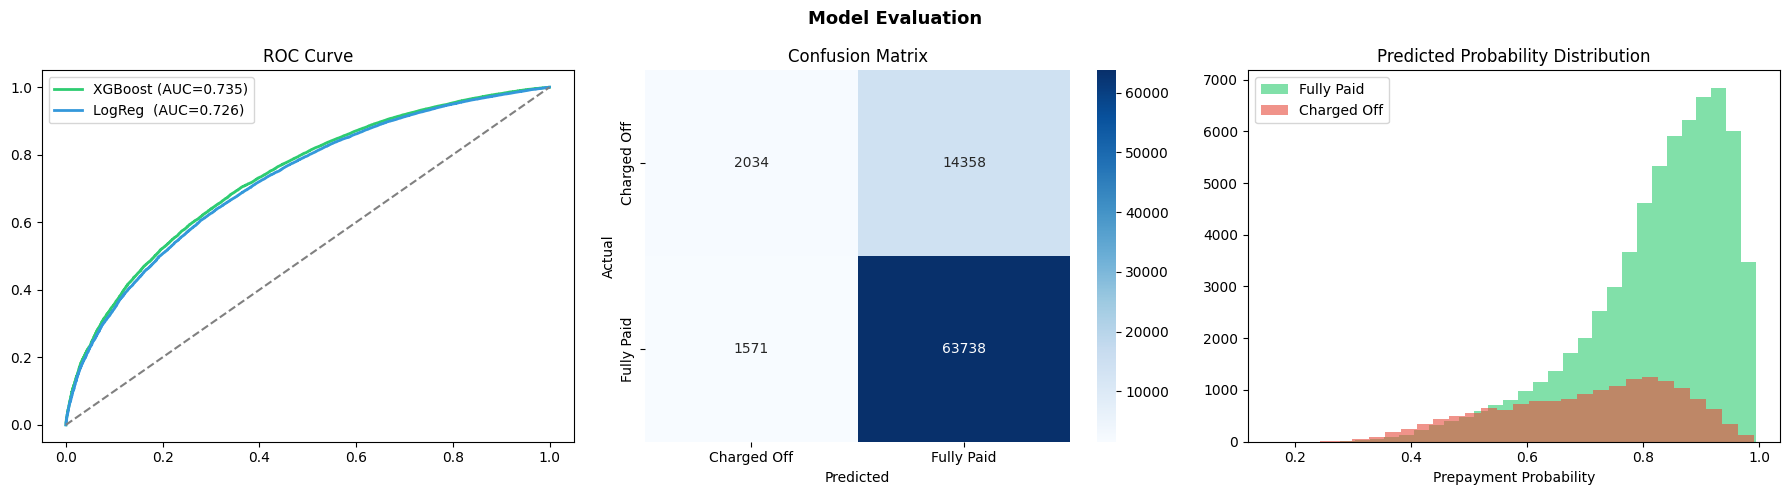

In [ ]:
print("--- Classification Report ---")
print(classification_report(y_test, xgb_pred, target_names=['Charged Off', 'Fully Paid']))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Model Evaluation', fontsize=13, fontweight='bold')

# ROC Curve
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)
fpr_lr,  tpr_lr,  _ = roc_curve(y_test, lr_proba)
axes[0].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC={xgb_auc:.3f})', color='#2ecc71', lw=2)
axes[0].plot(fpr_lr,  tpr_lr,  label=f'LogReg  (AUC={lr_auc:.3f})',  color='#3498db', lw=2)
axes[0].plot([0,1],[0,1],'--', color='gray')
axes[0].set_title('ROC Curve')
axes[0].legend()

# Confusion Matrix
cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(cm, annot=True, fmt='d', ax=axes[1],
            xticklabels=['Charged Off','Fully Paid'],
            yticklabels=['Charged Off','Fully Paid'],
            cmap='Blues')
axes[1].set_title('Confusion Matrix')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

# Probability Distribution
axes[2].hist(xgb_proba[y_test==1], bins=30, alpha=0.6, label='Fully Paid', color='#2ecc71')
axes[2].hist(xgb_proba[y_test==0], bins=30, alpha=0.6, label='Charged Off', color='#e74c3c')
axes[2].set_title('Predicted Probability Distribution')
axes[2].set_xlabel('Prepayment Probability')
axes[2].legend()

plt.tight_layout()
plt.show()

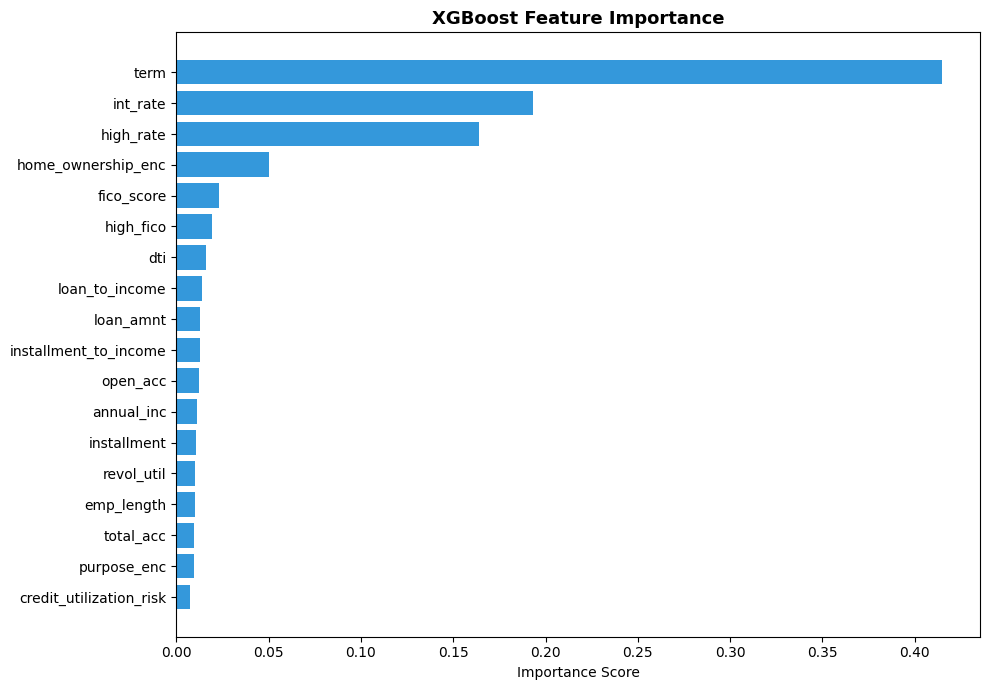

In [ ]:
importance_df = pd.DataFrame({
    'feature': FEATURES,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(importance_df['feature'], importance_df['importance'], color='#3498db')
plt.title('XGBoost Feature Importance', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

In [ ]:
sample = pd.DataFrame([{
    'loan_amnt': 15000,
    'int_rate': 22.5,
    'installment': 420.0,
    'annual_inc': 75000,
    'dti': 12.0,
    'fico_score': 740,
    'term': 36,
    'emp_length': 5,
    'open_acc': 10,
    'revol_util': 35.0,
    'total_acc': 20,
    'home_ownership_enc': le_home.transform(['MORTGAGE'])[0],
    'purpose_enc': le_purpose.transform(['debt_consolidation'])[0],
    'loan_to_income': 15000/75000,
    'installment_to_income': 420/(75000/12),
    'credit_utilization_risk': 0,
    'high_fico': 1,
    'high_rate': 1
}])

prob = xgb_model.predict_proba(sample)[0][1]
pred = "WILL FULLY PAY" if prob > 0.5 else "RISK OF DEFAULT ✗"

print(f"Prediction  : {pred}")
print(f"Probability : {prob:.2%}")

Prediction  : WILL FULLY PAY
Probability : 75.16%
